# ☕ Café Martínez — Auditoría de comentarios en Instagram

**Trabajo Integrador**

**Problema de negocio:** el dueño de Café Martínez publica en Instagram y recibe cientos de comentarios, pero nadie los lee uno por uno. No sabe si la gente habla bien o mal de la marca, ni qué publicación generó quejas.

**Solución:** este notebook audita las últimas 10 publicaciones y, de punta a punta:

1. Obtiene los comentarios de cada publicación.
2. Los limpia con pandas.
3. Los puntúa con una **red neuronal** en una escala de 0 a 1 (0 = muy negativo, 1 = muy positivo).
4. Calcula el puntaje de cada publicación y arma los gráficos.
5. Envía el reporte por email al dueño.

Para correrlo: **Entorno de ejecución → Ejecutar todo**. Streamlit github

## 0. Instalación y configuración

La única librería que hay que instalar es `pysentimiento`, que trae la red neuronal entrenada en español. Las demás ya vienen con Colab.

La instalación tarda unos 2 minutos. Si Colab pide reiniciar el entorno, reiniciá y volvé a ejecutar todo.

In [ ]:
!pip install -q pysentimiento

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

# --- Datos del negocio ---
NEGOCIO = "Café Martínez"
USUARIO_IG = "cafemartinez"
CANTIDAD_PUBLICACIONES = 10

# --- Umbrales de clasificación (escala 0 a 1) ---
UMBRAL_POSITIVO = 0.60   # de acá para arriba, el comentario es positivo
UMBRAL_NEGATIVO = 0.40   # de acá para abajo, es negativo

# --- Email (ver sección 6) ---
ENVIAR_EMAIL = False                      # cambiar a True para enviar de verdad
PROVEEDOR = "mailtrap"                    # "mailtrap" (sandbox de prueba) o "gmail" (envío real)
REMITENTE = "reportes@cafemartinez-auditoria.com"   # con Gmail tiene que ser tu propia dirección
DESTINATARIOS = ["dueno@cafemartinez.com"]          # con Gmail, usar tu propia casilla
CC = []                                   # copia visible (ej: ["gerente@cafemartinez.com"])
BCC = []                                  # copia oculta (ej: ["yo@gmail.com"])


## 1. Obtención de los comentarios

### 1.1 Por qué Instagram no se puede scrapear con `requests`

En el taller vimos que el scraping con `requests` + `BeautifulSoup` funciona cuando el servidor devuelve el HTML **ya armado**. Instagram no cumple ninguna de esas condiciones:

1. **Pide iniciar sesión.** Sin cuenta logueada devuelve una página de login, no los comentarios.
2. **Carga con JavaScript.** El HTML que llega viene casi vacío: los comentarios los agrega el navegador después, ejecutando código. `requests` no ejecuta JavaScript, así que nunca los ve.
3. **Lo prohíbe su `robots.txt`** y bloquea por cantidad de pedidos.

Lo comprobamos con el mismo chequeo del taller.

In [ ]:
# Chequeo de robots.txt, igual que en el taller
try:
    robots = requests.get("https://www.instagram.com/robots.txt", timeout=10)
    print(f"Status code: {robots.status_code}")
    print("--- Primeras líneas de robots.txt ---")
    print(robots.text[:400])
except requests.exceptions.RequestException as e:
    print(f"No se pudo consultar robots.txt: {e}")

Status code: 200
--- Primeras líneas de robots.txt ---
# Notice: Collection of data on Instagram through automated means is
# prohibited unless you have express written permission from Instagram
# and may only be conducted for the limited purpose contained in said
# permission.
# All authorized user-agents listed on this page must comply with Meta’s
# Automated Data Collection Terms available at:
# https://www.facebook.com/legal/automated_data_collect


In [ ]:
# Comprobamos que el HTML que llega NO tiene los comentarios
url_perfil = f"https://www.instagram.com/{USUARIO_IG}/"
headers = {"User-Agent": "Mozilla/5.0 (compatible; TP-UADE/1.0; trabajo educativo)"}

try:
    r = requests.get(url_perfil, headers=headers, timeout=10)
    r.encoding = "utf-8"
    print(f"Status code: {r.status_code}")
    print(f"Caracteres recibidos: {len(r.text)}")

    soup = BeautifulSoup(r.text, "html.parser")
    print(f"Título de la página: {soup.title.text if soup.title else 'sin título'}")

    # Buscamos comentarios en el HTML recibido
    comentarios_html = soup.find_all("span", class_="comment")
    print(f"Comentarios encontrados en el HTML: {len(comentarios_html)}")
except requests.exceptions.RequestException as e:
    print(f"Falló el pedido: {e}")

Status code: 429
Caracteres recibidos: 0
Título de la página: sin título
Comentarios encontrados en el HTML: 0


**Conclusión del chequeo:** el pedido devuelve HTML, pero sin ningún comentario adentro. Es el límite que el taller marca al final: cuando el contenido lo carga JavaScript, `requests` no alcanza.

### 1.2 Cómo se resuelve

Hay tres caminos para un caso real:

1. **API oficial de Instagram** (Graph API). Es lo correcto y lo que usaría la empresa, pero requiere una cuenta de empresa, una app de Meta aprobada y tokens de acceso.
2. **Exportar los comentarios a mano** desde la app y guardarlos en un CSV.
3. **Selenium**, que maneja un navegador real y sí ejecuta JavaScript. No lo vimos en clase y además viola los términos de Instagram.

Este notebook admite los dos primeros caminos de forma automática. Busca un archivo llamado **`comentarios_instagram.csv`** con estas columnas:

- `publicacion`: número de la publicación (1 a 10)
- `usuario`: quién comentó
- `comentario`: el texto del comentario

**Si el archivo existe**, usa esos comentarios reales (subilo desde el ícono de carpeta de Colab, en la barra izquierda, y volvé a ejecutar todo). **Si no existe**, usa comentarios simulados, como permite la consigna. De acá en adelante todo trabaja sobre el DataFrame, así que el resto del notebook funciona igual con datos reales.

### 1.3 Comentarios simulados (plan B si no hay CSV)

Simulamos 10 publicaciones con sus comentarios. Para que los datos se parezcan a los reales:

- Cada publicación tiene una cantidad distinta de comentarios.
- Dos publicaciones (la 4 y la 9) reciben más quejas que el resto, para que la auditoría tenga algo que detectar.
- Algunos comentarios vienen vacíos o son solo emojis, como pasa en Instagram.

In [ ]:
np.random.seed(42)

# Frases que la gente suele dejar en los comentarios
comentarios_positivos = [
    "Excelente atención, siempre vuelvo",
    "El mejor café de la zona",
    "Muy ricas las medialunas, recién hechas",
    "Me encanta este lugar, muy cómodo",
    "Atención de primera, gracias",
    "Buenísimo todo, lo recomiendo",
    "Qué lindo local, volvemos seguro",
    "El capuccino estaba perfecto",
    "Muy buena onda los chicos del mostrador",
    "Me fascina el aroma del café de ustedes",
]

comentarios_negativos = [
    "Esperé 40 minutos y nunca me atendieron",
    "Carísimo para lo que es",
    "El café estaba frío, muy mal",
    "Pésima atención, no vuelvo más",
    "Subieron todo de precio otra vez",
    "Las medialunas estaban duras",
    "Mucho ruido y las mesas sucias",
    "Pedí sin azúcar y me lo trajeron con azúcar",
    "Una decepción, esperaba más",
    "Tardaron muchísimo en traer el pedido",
]

comentarios_neutros = [
    "A qué hora abren los domingos",
    "Hacen delivery",
    "Tienen opciones sin TACC",
    "Dónde queda esta sucursal",
    "Cuánto sale el café con leche",
]

comentarios_basura = ["", "   ", "🔥🔥🔥", "❤️", "👏👏"]

In [ ]:
# Publicaciones: cuántos comentarios tiene cada una y qué porcentaje son quejas
publicaciones = []
for n in range(1, CANTIDAD_PUBLICACIONES + 1):
    if n == 4 or n == 9:
        porcentaje_negativo = 0.55      # publicaciones problemáticas
    else:
        porcentaje_negativo = 0.15
    publicaciones.append({
        "publicacion": n,
        "cantidad": np.random.randint(25, 60),
        "porc_negativo": porcentaje_negativo,
    })

# Armamos la lista de comentarios
filas = []
id_comentario = 1

for pub in publicaciones:
    for i in range(pub["cantidad"]):
        sorteo = np.random.randint(0, 100) / 100     # número al azar entre 0 y 0,99

        if sorteo < pub["porc_negativo"]:
            texto = comentarios_negativos[np.random.randint(0, len(comentarios_negativos))]
        elif sorteo < pub["porc_negativo"] + 0.12:
            texto = comentarios_neutros[np.random.randint(0, len(comentarios_neutros))]
        elif sorteo > 0.93:
            texto = comentarios_basura[np.random.randint(0, len(comentarios_basura))]
        else:
            texto = comentarios_positivos[np.random.randint(0, len(comentarios_positivos))]

        filas.append({
            "id_comentario": id_comentario,
            "publicacion": pub["publicacion"],
            "usuario": f"usuario_{np.random.randint(100, 999)}",
            "comentario": texto,
        })
        id_comentario = id_comentario + 1

comentarios = pd.DataFrame(filas)

# Agregamos duplicados, como pasa cuando alguien comenta dos veces por error
duplicados = comentarios.head(15)
comentarios = pd.concat([comentarios, duplicados], ignore_index=True)

comentarios_simulados = comentarios
print(f"Comentarios simulados generados: {len(comentarios)}")

Comentarios simulados generados: 440


### 1.4 Carga final: CSV real o simulados

Intentamos primero cargar el archivo real. Si no está, seguimos con los comentarios simulados y dejamos registrado el origen de los datos para el reporte.

In [ ]:
try:
    comentarios = pd.read_csv("comentarios_instagram.csv")
    origen_datos = "archivo comentarios_instagram.csv (datos reales)"
except FileNotFoundError:
    comentarios = comentarios_simulados
    origen_datos = "comentarios simulados de ejemplo"

print(f"Origen de los datos: {origen_datos}")
print(f"Comentarios obtenidos: {len(comentarios)}")
comentarios.head()

Origen de los datos: comentarios simulados de ejemplo
Comentarios obtenidos: 440


,id_comentario,publicacion,usuario,comentario
0,1,1,usuario_408,Las medialunas estaban duras
1,2,1,usuario_591,Pedí sin azúcar y me lo trajeron con azúcar
2,3,1,usuario_485,"Buenísimo todo, lo recomiendo"
3,4,1,usuario_260,"Atención de primera, gracias"
4,5,1,usuario_121,Me fascina el aroma del café de ustedes


## 2. Procesamiento y limpieza

### 2.1 Exploración
Primero miramos qué tenemos, antes de tocar nada.

In [ ]:
print("Forma:", comentarios.shape)
print()
print(comentarios.info())

Forma: (440, 4)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_comentario  440 non-null    int64 
 1   publicacion    440 non-null    int64 
 2   usuario        440 non-null    object
 3   comentario     440 non-null    object
dtypes: int64(2), object(2)
memory usage: 13.9+ KB
None


In [ ]:
print("Comentarios por publicación:")
print(comentarios["publicacion"].value_counts().sort_index())

Comentarios por publicación:
publicacion
1     68
2     39
3     32
4     45
5     43
6     47
7     35
8     35
9     48
10    48
Name: count, dtype: int64


### 2.2 Limpieza

Tres problemas a resolver, los mismos que vimos con los libros:

1. **Comentarios duplicados:** una fila exactamente igual a otra (mismo usuario, misma publicación y mismo texto) se cuenta una sola vez, con `duplicated()`.
2. **Comentarios vacíos:** no se pueden analizar.
3. **Comentarios sin texto real:** los que son solo emojis no aportan opinión. Los detectamos con `.str.len()` después de limpiar los espacios con `.str.strip()`.

In [ ]:
print("Filas totales:        ", len(comentarios))
print("Filas repetidas:      ", comentarios.duplicated().sum())

# 1) Sacamos los duplicados
df = comentarios[comentarios.duplicated() == False]

# 2) Limpiamos los espacios de los extremos (como el .strip() del scraping)
df = df.copy()
df["comentario"] = df["comentario"].str.strip()

# 3) Nos quedamos solo con los que tienen texto suficiente
df["largo"] = df["comentario"].str.len()
print("Comentarios vacíos:   ", len(df[df["largo"] == 0]))
print("Solo emojis o muy cortos:", len(df[(df["largo"] > 0) & (df["largo"] < 10)]))

df = df[df["largo"] >= 10]

df = df.reset_index()
df = df.drop(["index"], axis=1)

print()
print("Comentarios listos para analizar:", len(df))
df.head()

Filas totales:         440
Filas repetidas:       15
Comentarios vacíos:    13
Solo emojis o muy cortos: 17

Comentarios listos para analizar: 395


,id_comentario,publicacion,usuario,comentario,largo
0,1,1,usuario_408,Las medialunas estaban duras,28
1,2,1,usuario_591,Pedí sin azúcar y me lo trajeron con azúcar,43
2,3,1,usuario_485,"Buenísimo todo, lo recomiendo",29
3,4,1,usuario_260,"Atención de primera, gracias",28
4,5,1,usuario_121,Me fascina el aroma del café de ustedes,39


## 3. Análisis de sentimiento con una red neuronal

### 3.1 Qué modelo usamos

Usamos **`pysentimiento`**, una librería que trae una red neuronal del tipo BERT entrenada con millones de tuits en español. Es importante que sea en español: un modelo entrenado en inglés no entiende "carísimo" ni "la rompieron".

El modelo recibe un comentario y devuelve tres probabilidades, que suman 1: la de que sea positivo (POS), neutro (NEU) o negativo (NEG).

**Cómo armamos el puntaje de 0 a 1:** nos quedamos con la probabilidad de POS. Si el modelo está 95% seguro de que un comentario es positivo, el puntaje es 0,95. Si está seguro de que es negativo, la probabilidad de POS es baja y el puntaje queda cerca de 0.

Igual que en cualquier sistema con IA, agregamos un **plan B**: si el modelo no se puede cargar (sin internet, o falló la instalación), el notebook calcula el puntaje con un diccionario de palabras positivas y negativas. El reporte sale igual, con menos precisión, y el notebook avisa qué método usó.

In [ ]:
# Diccionario para el plan B: palabras que indican opinión
palabras_positivas = ["excelente", "mejor", "rico", "ricas", "encanta", "fascina", "lindo",
                      "perfecto", "buenísimo", "recomiendo", "gracias", "buena", "cómodo", "vuelvo"]
palabras_negativas = ["esperé", "nunca", "carísimo", "frío", "pésima", "mal", "duras",
                      "sucias", "decepción", "tardaron", "ruido", "no vuelvo", "subieron"]


def puntaje_con_palabras(texto):
    # Plan B: cuenta palabras positivas y negativas y arma un puntaje de 0 a 1
    texto = texto.lower()
    positivas = 0
    negativas = 0

    for palabra in palabras_positivas:
        if palabra in texto:
            positivas = positivas + 1

    for palabra in palabras_negativas:
        if palabra in texto:
            negativas = negativas + 1

    if positivas == 0 and negativas == 0:
        return 0.5                                  # sin pistas: neutro
    return positivas / (positivas + negativas)


def cargar_modelo():
    # Intenta cargar la red neuronal; si falla, devuelve None
    try:
        from pysentimiento import create_analyzer
        modelo = create_analyzer(task="sentiment", lang="es")
        return modelo
    except Exception as error:
        print(f"No se pudo cargar la red neuronal ({type(error).__name__}).")
        print("Se usa el plan B: puntaje por diccionario de palabras.")
        return None


modelo = cargar_modelo()

if modelo is None:
    metodo = "diccionario de palabras (plan B)"
else:
    metodo = "red neuronal (pysentimiento, BERT en español)"

print(f"Método de análisis: {metodo}")

config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Método de análisis: red neuronal (pysentimiento, BERT en español)


### 3.2 Puntuamos los comentarios

Recorremos los comentarios y le pedimos a la red neuronal el puntaje de cada uno. Puede tardar un par de minutos la primera vez, porque además descarga el modelo.

In [ ]:
puntajes = []

for texto in df["comentario"]:
    if modelo is None:
        puntajes.append(puntaje_con_palabras(texto))
    else:
        resultado = modelo.predict(texto)
        puntajes.append(resultado.probas["POS"])     # probabilidad de ser positivo: 0 a 1

df["puntaje"] = puntajes
df["puntaje"] = df["puntaje"].round(3)

print("Comentarios puntuados:", len(df))
df[["publicacion", "comentario", "puntaje"]].head(10)

Comentarios puntuados: 395


,publicacion,comentario,puntaje
0,1,Las medialunas estaban duras,0.023
1,1,Pedí sin azúcar y me lo trajeron con azúcar,0.018
2,1,"Buenísimo todo, lo recomiendo",0.978
3,1,"Atención de primera, gracias",0.735
4,1,Me fascina el aroma del café de ustedes,0.969
5,1,"Excelente atención, siempre vuelvo",0.803
6,1,Me fascina el aroma del café de ustedes,0.969
7,1,"Muy ricas las medialunas, recién hechas",0.949
8,1,"Me encanta este lugar, muy cómodo",0.977
9,1,Subieron todo de precio otra vez,0.008


### 3.3 Clasificamos cada comentario

El puntaje es un número con decimales, y para el reporte conviene una etiqueta. Usamos los umbrales de la sección 0: arriba de 0,60 es positivo, abajo de 0,40 es negativo, y en el medio es neutro.

In [ ]:
def clasificar(puntaje):
    if puntaje >= UMBRAL_POSITIVO:
        return "Positivo"
    elif puntaje <= UMBRAL_NEGATIVO:
        return "Negativo"
    else:
        return "Neutro"


sentimientos = []
for p in df["puntaje"]:
    sentimientos.append(clasificar(p))

df["sentimiento"] = sentimientos

print(df["sentimiento"].value_counts())
print()
print("Distribución del puntaje:")
print(df["puntaje"].describe().round(3))

sentimiento
Positivo    233
Negativo    162
Name: count, dtype: int64

Distribución del puntaje:
count    395.000
mean       0.543
std        0.434
min        0.004
25%        0.018
50%        0.803
75%        0.946
max        0.978
Name: puntaje, dtype: float64


## 4. Resultados de la auditoría

### 4.1 Puntaje general de la marca

In [ ]:
puntaje_general = df["puntaje"].mean()
total_comentarios = len(df)

positivos = len(df[df["sentimiento"] == "Positivo"])
negativos = len(df[df["sentimiento"] == "Negativo"])
neutros = len(df[df["sentimiento"] == "Neutro"])

porc_positivos = positivos / total_comentarios * 100
porc_negativos = negativos / total_comentarios * 100

print(f"=== Auditoría de {NEGOCIO} en Instagram ===")
print(f"Publicaciones auditadas: {CANTIDAD_PUBLICACIONES}")
print(f"Comentarios analizados:  {total_comentarios}")
print()
print(f"Puntaje general: {puntaje_general:.3f} (escala 0 a 1)")
print(f"Positivos: {positivos} ({porc_positivos:.1f}%)")
print(f"Neutros:   {neutros}")
print(f"Negativos: {negativos} ({porc_negativos:.1f}%)")

=== Auditoría de Café Martínez en Instagram ===
Publicaciones auditadas: 10
Comentarios analizados:  395

Puntaje general: 0.543 (escala 0 a 1)
Positivos: 233 (59.0%)
Neutros:   0
Negativos: 162 (41.0%)


### 4.2 Puntaje por publicación
Acá está lo que el promedio general esconde: qué publicación generó quejas.

In [ ]:
por_pub = pd.DataFrame({
    "comentarios": df.groupby("publicacion")["puntaje"].count(),
    "puntaje": df.groupby("publicacion")["puntaje"].mean().round(3),
})

# Cantidad de negativos por publicación
solo_negativos = df[df["sentimiento"] == "Negativo"]
por_pub["negativos"] = solo_negativos.groupby("publicacion")["puntaje"].count()
por_pub["negativos"] = por_pub["negativos"].fillna(0).astype(int)
por_pub["porc_negativos"] = (por_pub["negativos"] / por_pub["comentarios"] * 100).round(1)

por_pub = por_pub.sort_values("puntaje")

peor_publicacion = por_pub.index[0]
mejor_publicacion = por_pub.index[-1]

por_pub

,comentarios,puntaje,negativos,porc_negativos
publicacion,,,,
9,47,0.136,41,87.2
4,40,0.196,32,80.0
8,33,0.594,12,36.4
6,44,0.629,13,29.5
5,39,0.630,12,30.8
3,28,0.634,8,28.6
1,49,0.657,14,28.6
2,35,0.667,10,28.6
7,33,0.671,9,27.3


### 4.3 Los 5 comentarios más negativos
Son los que el dueño debería leer y responder primero.

In [ ]:
peores = df.sort_values("puntaje")[["publicacion", "usuario", "comentario", "puntaje"]].head(5)
peores

,publicacion,usuario,comentario,puntaje
39,1,usuario_894,Mucho ruido y las mesas sucias,0.004
345,9,usuario_388,Mucho ruido y las mesas sucias,0.004
338,9,usuario_297,Mucho ruido y las mesas sucias,0.004
93,3,usuario_294,Mucho ruido y las mesas sucias,0.004
120,4,usuario_953,Mucho ruido y las mesas sucias,0.004


### 4.4 Guardamos los resultados
Exportamos a CSV para que el dueño pueda abrirlo en Excel y ver el detalle.

In [ ]:
df.to_csv("comentarios_analizados.csv", index=False)
por_pub.to_csv("resumen_por_publicacion.csv")
print("Archivos guardados: comentarios_analizados.csv y resumen_por_publicacion.csv")

Archivos guardados: comentarios_analizados.csv y resumen_por_publicacion.csv


## 5. Visualizaciones

Tres gráficos, uno por pregunta: ¿cómo se reparten las opiniones?, ¿qué publicación anduvo peor?, ¿cómo se distribuyen los puntajes?

Cada gráfico se guarda como imagen para adjuntarlo en el email.

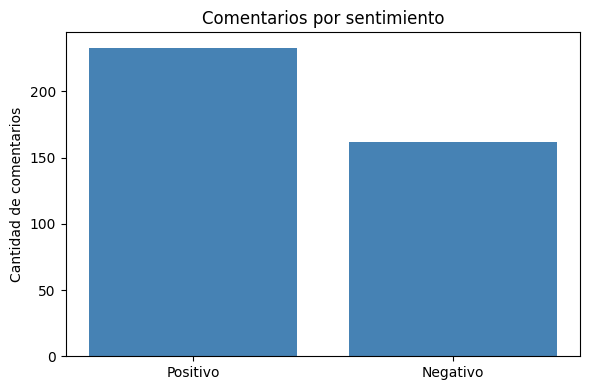

In [ ]:
archivos = []

# 1) Cantidad de comentarios por sentimiento
conteo = df["sentimiento"].value_counts()
plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color="steelblue")
plt.title("Comentarios por sentimiento")
plt.ylabel("Cantidad de comentarios")
plt.tight_layout()
plt.savefig("grafico_sentimiento.png")
archivos.append("grafico_sentimiento.png")
plt.show()

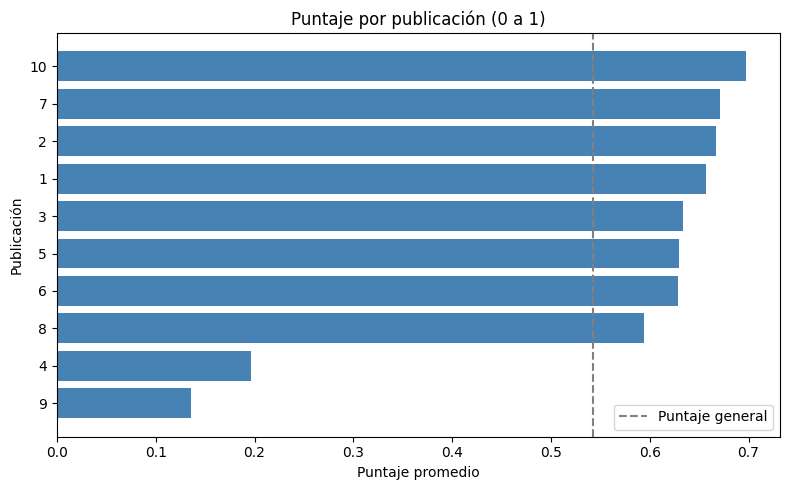

In [ ]:
# 2) Puntaje promedio por publicación
plt.figure(figsize=(8, 5))
plt.barh(por_pub.index.astype(str), por_pub["puntaje"], color="steelblue")
plt.axvline(puntaje_general, color="gray", linestyle="--", label="Puntaje general")
plt.title("Puntaje por publicación (0 a 1)")
plt.xlabel("Puntaje promedio")
plt.ylabel("Publicación")
plt.legend()
plt.tight_layout()
plt.savefig("grafico_publicaciones.png")
archivos.append("grafico_publicaciones.png")
plt.show()

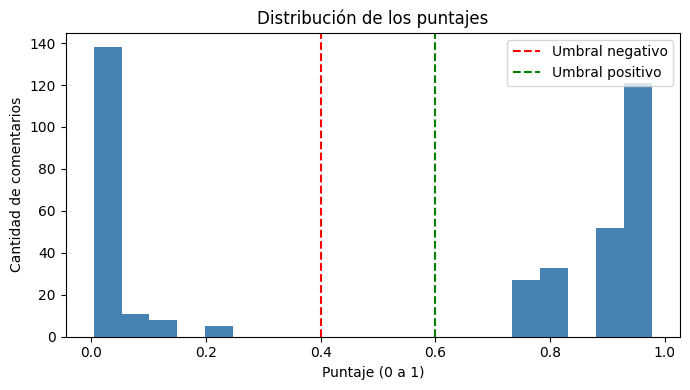

In [ ]:
# 3) Distribución de los puntajes
plt.figure(figsize=(7, 4))
plt.hist(df["puntaje"], bins=20, color="steelblue")
plt.axvline(UMBRAL_NEGATIVO, color="red", linestyle="--", label="Umbral negativo")
plt.axvline(UMBRAL_POSITIVO, color="green", linestyle="--", label="Umbral positivo")
plt.title("Distribución de los puntajes")
plt.xlabel("Puntaje (0 a 1)")
plt.ylabel("Cantidad de comentarios")
plt.legend()
plt.tight_layout()
plt.savefig("grafico_distribucion.png")
archivos.append("grafico_distribucion.png")
plt.show()

## 6. Envío automático del reporte por email

Armamos el email con el resumen de la auditoría y los gráficos adjuntos, igual que en la clase de automatización de emails: `EmailMessage` para armar el mensaje y `smtplib` para enviarlo.

**Primero se prueba en Mailtrap, después se manda de verdad por Gmail** (cambian el host, el puerto y las credenciales; el resto del código es el mismo):

1. **Mailtrap (sandbox, recomendado para la demo):** en mailtrap.io, *Email Testing → My Sandbox → Integration → SMTP* están el usuario y la contraseña. El mail queda atrapado en la bandeja del sandbox y no le llega a nadie.
2. **Gmail (envío real):** hace falta una **contraseña de aplicación** (https://myaccount.google.com/apppasswords, requiere verificación en dos pasos). No sirve la contraseña normal. El `REMITENTE` tiene que ser tu propia dirección de Gmail.

Para enviar: en la sección 0 poner `ENVIAR_EMAIL = True` y elegir `PROVEEDOR`. Las credenciales se piden con `getpass`, nunca se escriben en el código.

Con `ENVIAR_EMAIL = False` solo se muestra una vista previa.

In [ ]:
# Armamos el resumen en texto a partir de los números calculados
if puntaje_general >= UMBRAL_POSITIVO:
    diagnostico = "La percepción de la marca es buena"
elif puntaje_general <= UMBRAL_NEGATIVO:
    diagnostico = "La percepción de la marca es mala y requiere atención urgente"
else:
    diagnostico = "La percepción de la marca es intermedia"

resumen = (f"Sobre las últimas {CANTIDAD_PUBLICACIONES} publicaciones de {NEGOCIO} se analizaron "
           f"{total_comentarios} comentarios con un puntaje general de {puntaje_general:.2f} sobre 1. "
           f"{diagnostico}: el {porc_positivos:.1f}% de los comentarios son positivos "
           f"y el {porc_negativos:.1f}% son negativos. "
           f"La publicación con mejor recepción fue la N° {mejor_publicacion} "
           f"({por_pub.loc[mejor_publicacion, 'puntaje']:.2f}) y la peor fue la N° {peor_publicacion} "
           f"({por_pub.loc[peor_publicacion, 'puntaje']:.2f}, con "
           f"{por_pub.loc[peor_publicacion, 'porc_negativos']}% de comentarios negativos).")

if por_pub.loc[peor_publicacion, "porc_negativos"] > 30:
    resumen = resumen + (f" Recomendación: revisar qué se publicó y qué pasó en el local "
                         f"alrededor de la publicación N° {peor_publicacion}, y responder los "
                         f"comentarios negativos listados en el archivo adjunto.")
else:
    resumen = resumen + " Recomendación: mantener la estrategia actual y seguir monitoreando."

print(resumen)

Sobre las últimas 10 publicaciones de Café Martínez se analizaron 395 comentarios con un puntaje general de 0.54 sobre 1. La percepción de la marca es intermedia: el 59.0% de los comentarios son positivos y el 41.0% son negativos. La publicación con mejor recepción fue la N° 10 (0.70) y la peor fue la N° 9 (0.14, con 87.2% de comentarios negativos). Recomendación: revisar qué se publicó y qué pasó en el local alrededor de la publicación N° 9, y responder los comentarios negativos listados en el archivo adjunto.


In [ ]:
import smtplib
import time
from email.message import EmailMessage
from getpass import getpass
from IPython.display import HTML, display

asunto = f"Auditoría de Instagram — {NEGOCIO} — últimas {CANTIDAD_PUBLICACIONES} publicaciones"

# Una fila de tabla por publicación
filas_pub = ""
for pub in por_pub.index:
    puntaje_pub = por_pub.loc[pub, "puntaje"]
    cant = por_pub.loc[pub, "comentarios"]
    porc = por_pub.loc[pub, "porc_negativos"]
    filas_pub = filas_pub + f"<tr><td>{pub}</td><td>{cant}</td><td>{puntaje_pub}</td><td>{porc}%</td></tr>"

# Los 3 comentarios más negativos, para el cuerpo del email
filas_peores = ""
for i in peores.head(3).index:
    filas_peores = filas_peores + f"<li>Publicación {peores.loc[i, 'publicacion']}: \"{peores.loc[i, 'comentario']}\" (puntaje {peores.loc[i, 'puntaje']})</li>"

cuerpo_html = f"""
<h2>{NEGOCIO} — Auditoría de comentarios en Instagram</h2>
<p><b>Últimas {CANTIDAD_PUBLICACIONES} publicaciones · {total_comentarios} comentarios analizados</b></p>
<p>{resumen}</p>
<h3>Indicadores</h3>
<ul>
  <li>Puntaje general: <b>{puntaje_general:.2f}</b> (escala 0 a 1)</li>
  <li>Comentarios positivos: <b>{positivos}</b> ({porc_positivos:.1f}%)</li>
  <li>Comentarios negativos: <b>{negativos}</b> ({porc_negativos:.1f}%)</li>
  <li>Método de análisis: {metodo}</li>
  <li>Origen de los datos: {origen_datos}</li>
</ul>
<h3>Detalle por publicación</h3>
<table border="1" cellpadding="6" style="border-collapse:collapse">
  <tr><th>Publicación</th><th>Comentarios</th><th>Puntaje</th><th>% negativos</th></tr>
  {filas_pub}
</table>
<h3>Comentarios que requieren respuesta</h3>
<ul>{filas_peores}</ul>
<p>Los gráficos van adjuntos.</p>
<p><i>Reporte generado automáticamente.</i></p>
"""

mensaje = EmailMessage()
mensaje["Subject"] = asunto
mensaje["From"] = REMITENTE
mensaje["To"] = ", ".join(DESTINATARIOS)
if CC:
    mensaje["Cc"] = ", ".join(CC)
if BCC:
    mensaje["Bcc"] = ", ".join(BCC)    # send_message() lo usa para entregar y lo borra del mensaje
mensaje.set_content(resumen)                       # versión en texto plano
mensaje.add_alternative(cuerpo_html, subtype="html")

for archivo in archivos:
    with open(archivo, "rb") as f:
        mensaje.add_attachment(f.read(), maintype="image", subtype="png", filename=archivo)


### 6.1 Envío con manejo de errores y reintentos

Un reporte que se manda solo tiene que anticipar fallas: contraseña equivocada, destinatario inválido, servidor saturado. Por eso el envío va dentro de una función con `try/except` (como `enviar_reporte` de la clase) y otra que **reintenta con espera creciente** (*backoff*) cuando el error es pasajero, por ejemplo el `550 Too many emails per second` de Mailtrap.

Un error de contraseña no se reintenta: va a fallar igual y varios logins fallidos seguidos pueden bloquear la cuenta.

In [ ]:
PROVEEDORES = {
    "mailtrap": {"host": "sandbox.smtp.mailtrap.io", "puerto": 587},
    "gmail":    {"host": "smtp.gmail.com",           "puerto": 587},
}

def enviar_reporte(mensaje, host, puerto, usuario, password):
    """Envía un EmailMessage ya armado. Devuelve "ok", "reintentar" o "fallo_definitivo"."""
    try:
        with smtplib.SMTP(host, puerto, timeout=10) as servidor:
            servidor.starttls()                    # activa el cifrado de la conexión
            servidor.login(usuario, password)
            servidor.send_message(mensaje)
        print("✅ Enviado correctamente")
        return "ok"
    except smtplib.SMTPAuthenticationError:
        print("❌ Usuario o contraseña incorrectos (no se reintenta)")
        return "fallo_definitivo"
    except smtplib.SMTPRecipientsRefused:
        print("❌ El servidor rechazó a uno o más destinatarios: revisá las direcciones (no se reintenta)")
        return "fallo_definitivo"
    except smtplib.SMTPException as e:
        print(f"❌ Error de SMTP: {e}")
        return "reintentar"
    except Exception as e:
        print(f"❌ Error inesperado: {e}")
        return "reintentar"


def enviar_con_reintentos(mensaje, host, puerto, usuario, password, intentos=3, espera_inicial=5):
    """Reintenta con espera creciente, salvo en errores que no se arreglan esperando."""
    for intento in range(1, intentos + 1):
        resultado = enviar_reporte(mensaje, host, puerto, usuario, password)
        if resultado == "ok":
            return True
        if resultado == "fallo_definitivo":
            return False
        if intento < intentos:
            espera = espera_inicial * intento
            print(f"Reintentando en {espera} segundos... (intento {intento}/{intentos})")
            time.sleep(espera)
    print("Se agotaron los reintentos.")
    return False


if ENVIAR_EMAIL:
    config = PROVEEDORES[PROVEEDOR]
    if PROVEEDOR == "gmail":
        usuario_smtp = REMITENTE
        clave = getpass("Contraseña de aplicación de Gmail: ")
    else:
        usuario_smtp = getpass("Usuario SMTP de Mailtrap: ")
        clave = getpass("Contraseña SMTP de Mailtrap: ")

    enviado = enviar_con_reintentos(mensaje, config["host"], config["puerto"], usuario_smtp, clave)
    if enviado:
        print(f"Email enviado a: {', '.join(DESTINATARIOS)} (proveedor: {PROVEEDOR})")
else:
    print("ENVIAR_EMAIL = False: no se envió nada. Vista previa del email:\n")
    print(f"Asunto: {asunto}")
    print(f"Adjuntos: {', '.join(archivos)}")
    display(HTML(cuerpo_html))

## 7. Conclusiones

- **Qué resuelve:** leer cientos de comentarios a mano es inviable, así que nadie los lee. El sistema los audita todos en minutos y le dice al dueño en un número cómo está percibida la marca.
- **Qué detecta:** el promedio general esconde los problemas puntuales. Al abrir el puntaje por publicación, una publicación con muchas quejas queda a la vista aunque el resto haya andado bien.
- **Rol de la red neuronal:** entiende el texto de cada comentario y devuelve una probabilidad. No calcula los promedios ni arma el reporte: de eso se encarga pandas. Así se evita que el modelo invente números.
- **Por qué un modelo en español:** las redes entrenadas en inglés no interpretan bien el español rioplatense; `pysentimiento` está entrenada con tuits en español.
- **Limitaciones:** Instagram no permite scraping con `requests` (lo comprobamos en la sección 1), por eso los comentarios se cargan desde un CSV exportado o se simulan. Para usarlo en producción habría que conectar la API oficial de Instagram, y el resto del notebook funciona igual. Además, el modelo puede equivocarse con la ironía y los modismos.
- **Próximos pasos:** programar la ejecución automática todas las semanas, sumar las menciones de otras redes y comparar la evolución del puntaje mes a mes.